In [1]:
import pandas as pd
import numpy as np
import warnings

from pathlib import Path

project_path = Path.cwd()

if project_path.name == "notebooks":
    project_path = project_path.parent

data_path = project_path / "data" / "processed"
models_path = project_path / "models"
reports_path = project_path / "docs"

models_path.mkdir(parents=True, exist_ok=True)
reports_path.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(data_path / "train.csv")
val_df = pd.read_csv(data_path / "validation.csv")
aug_df = pd.read_csv(
    data_path / "augmentation_candidates_corrected.csv"
)

# Training origjinal
X_train = train_df["text"]
y_train = train_df["label"]

# Validation i pandryshuar
X_val = val_df["text"]
y_val = val_df["label"]

# Training i zgjeruar me Augmentation
augmented_train_df = pd.concat([
    train_df[["label", "text"]],
    aug_df[["label", "text"]]
], ignore_index=True)

X_train_aug = augmented_train_df["text"]
y_train_aug = augmented_train_df["label"]

print("Original Training:", len(X_train))
print("Augmented Training:", len(X_train_aug))
print("Validation:", len(X_val))
print("Classes:", y_train.nunique())

Original Training: 803
Augmented Training: 895
Validation: 178
Classes: 24


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

def create_models():
    return {
        "SVM": Pipeline([
            ("tfidf", TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 1),
                min_df=1
            )),
            ("classifier", LinearSVC(
                C=10,
                random_state=42
            ))
        ]),

        "Logistic Regression": Pipeline([
            ("tfidf", TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 1),
                min_df=1
            )),
            ("classifier", LogisticRegression(
                C=10,
                max_iter=2000,
                random_state=42
            ))
        ]),

        "KNN": Pipeline([
            ("tfidf", TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 1)
            )),
            ("classifier", KNeighborsClassifier(
                n_neighbors=1,
                weights="uniform",
                metric="cosine"
            ))
        ]),

        "Random Forest": Pipeline([
            ("tfidf", TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 2)
            )),
            ("classifier", RandomForestClassifier(
                n_estimators=200,
                max_depth=None,
                min_samples_leaf=1,
                random_state=42,
                n_jobs=-1
            ))
        ]),

        "Neural Network (MLP)": Pipeline([
            ("tfidf", TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 1),
                max_features=2000
            )),
            ("classifier", MLPClassifier(
                hidden_layer_sizes=(64,),
                alpha=0.01,
                activation="relu",
                solver="adam",
                max_iter=400,
                random_state=42
            ))
        ])
    }

print("Models prepared:", len(create_models()))

Models prepared: 5


In [3]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

results = []

for model_name in create_models().keys():

    print(f"\nTraining: {model_name}")

    # Modeli pa Augmentation
    model_original = create_models()[model_name]

    model_original.fit(X_train, y_train)
    pred_original = model_original.predict(X_val)

    # Modeli me Augmentation
    model_augmented = create_models()[model_name]

    model_augmented.fit(X_train_aug, y_train_aug)
    pred_augmented = model_augmented.predict(X_val)

    for experiment, predictions in [
        ("Original", pred_original),
        ("Augmented", pred_augmented)
    ]:
        results.append({
            "Model": model_name,
            "Training": experiment,
            "Accuracy": accuracy_score(y_val, predictions),
            "Precision": precision_score(
                y_val, predictions,
                average="macro",
                zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions,
                average="macro",
                zero_division=0
            ),
            "Macro F1": f1_score(
                y_val, predictions,
                average="macro",
                zero_division=0
            )
        })

    print(f"Completed: {model_name}")

results_df = pd.DataFrame(results)

display(results_df.round(4))


Training: SVM
Completed: SVM

Training: Logistic Regression
Completed: Logistic Regression

Training: KNN
Completed: KNN

Training: Random Forest
Completed: Random Forest

Training: Neural Network (MLP)
Completed: Neural Network (MLP)


,Model,Training,Accuracy,Precision,Recall,Macro F1
0,SVM,Original,0.9944,0.9962,0.9948,0.9952
1,SVM,Augmented,0.9944,0.9962,0.9948,0.9952
2,Logistic Regression,Original,0.9775,0.9805,0.9809,0.9787
3,Logistic Regression,Augmented,0.9831,0.9855,0.9855,0.9846
4,KNN,Original,0.9775,0.9815,0.9774,0.9777
5,KNN,Augmented,0.9775,0.9815,0.9774,0.9777
6,Random Forest,Original,0.9382,0.9458,0.9419,0.9386
7,Random Forest,Augmented,0.9326,0.9436,0.9347,0.9331
8,Neural Network (MLP),Original,0.9775,0.9803,0.9809,0.9790
9,Neural Network (MLP),Augmented,0.9775,0.9789,0.9786,0.9772


In [4]:
comparison = results_df.pivot(
    index="Model",
    columns="Training",
    values=["Accuracy", "Macro F1"]
)

comparison.columns = [
    f"{metric}_{training}"
    for metric, training in comparison.columns
]

comparison["Accuracy_Change"] = (
    comparison["Accuracy_Augmented"]
    - comparison["Accuracy_Original"]
)

comparison["MacroF1_Change"] = (
    comparison["Macro F1_Augmented"]
    - comparison["Macro F1_Original"]
)

comparison = comparison.sort_values(
    "MacroF1_Change",
    ascending=False
)

display(comparison.round(4))

,Accuracy_Augmented,Accuracy_Original,Macro F1_Augmented,Macro F1_Original,Accuracy_Change,MacroF1_Change
Model,,,,,,
Logistic Regression,0.9831,0.9775,0.9846,0.9787,0.0056,0.0059
KNN,0.9775,0.9775,0.9777,0.9777,0.0000,0.0000
SVM,0.9944,0.9944,0.9952,0.9952,0.0000,0.0000
Neural Network (MLP),0.9775,0.9775,0.9772,0.9790,0.0000,-0.0018
Random Forest,0.9326,0.9382,0.9331,0.9386,-0.0056,-0.0054


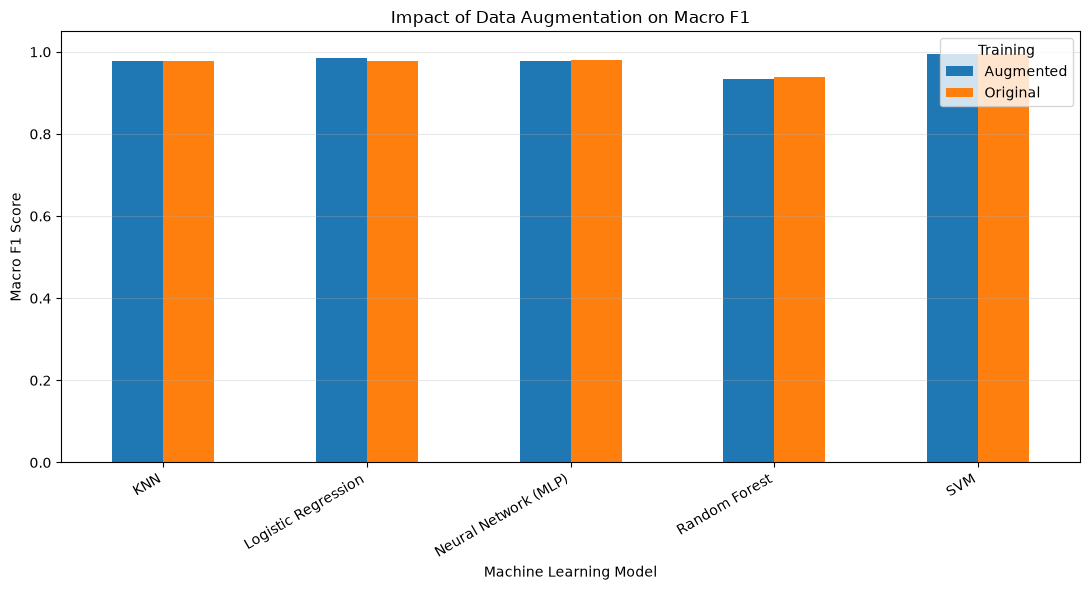

In [5]:
import matplotlib.pyplot as plt

plot_data = results_df.pivot(
    index="Model",
    columns="Training",
    values="Macro F1"
)

plot_data.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Impact of Data Augmentation on Macro F1")
plt.xlabel("Machine Learning Model")
plt.ylabel("Macro F1 Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
class_distribution = pd.DataFrame({
    "Original": y_train.value_counts(),
    "Augmented": y_train_aug.value_counts()
}).fillna(0).astype(int)

class_distribution["Added Samples"] = (
    class_distribution["Augmented"]
    - class_distribution["Original"]
)

class_distribution = class_distribution.sort_index()

display(class_distribution)

print("Original total:", class_distribution["Original"].sum())
print("Augmented total:", class_distribution["Augmented"].sum())
print("Added samples:", class_distribution["Added Samples"].sum())

,Original,Augmented,Added Samples
label,,,
Acne,34,35,1
Arthritis,29,35,6
Bronchial Asthma,33,34,1
Cervical spondylosis,34,45,11
Chicken pox,33,35,2
Common Cold,31,34,3
Dengue,33,41,8
Dimorphic Hemorrhoids,26,31,5
Fungal infection,39,41,2


Original total: 803
Augmented total: 895
Added samples: 92


In [7]:
results_df.to_csv(
    models_path / "augmentation_all_models_results.csv",
    index=False
)

comparison.to_csv(
    models_path / "augmentation_impact_comparison.csv"
)

class_distribution.to_csv(
    models_path / "augmentation_class_distribution.csv"
)

report_path = reports_path / "augmentation_impact_report.txt"

with open(report_path, "w", encoding="utf-8") as f:
    f.write("DATA AUGMENTATION IMPACT ANALYSIS\n")
    f.write("=" * 50 + "\n\n")

    f.write("TRAINING DATA\n")
    f.write(f"Original: {len(X_train)}\n")
    f.write(f"Augmented: {len(X_train_aug)}\n")
    f.write(f"Validation: {len(X_val)}\n\n")

    f.write("MODEL RESULTS\n")
    f.write(results_df.to_string(index=False))
    f.write("\n\nCOMPARISON\n")
    f.write(comparison.to_string())
    f.write("\n\nCLASS DISTRIBUTION\n")
    f.write(class_distribution.to_string())

print("Results saved successfully!")
print("Report:", report_path)

Results saved successfully!
Report: c:\Projects\Bachelor-Thesis\docs\augmentation_impact_report.txt
